# HW2 — Classifying Rice Variety with Logistic Regression
**FRA503 Introduction to Machine Learning (1/2569)**

*Phattanarat Jeedjeen 68340700410*

---


## Table of contents
- [1. Problem statement](#1--problem-statement)
- [2. Data loading & quality audit](#2--data-loading--quality-audit)
- [3. Train / test split](#3--train--test-split)
- [4. Target distribution](#4--target-distribution)
- [5. Initial feature exploration](#5--initial-feature-exploration)
- [6. Outlier analysis](#6--outlier-analysis)
- [7. Missing-value analysis](#7--missing-value-analysis)
- [8. Feature selection — continuous features](#8--feature-selection--continuous-features)
- [9. Feature selection — categorical features](#9--feature-selection--categorical-features)
- [10. Redundant-feature analysis](#10--redundant-feature-analysis)
- [11. Feature extraction](#11--feature-extraction)
- [12. Data pre-processing for ML](#12--data-pre-processing-for-ml)
- [13. Model building & training](#13--model-building-and-training)
- [14. Results and presentation](#14--results-and-presentation)
- [15. Discussion](#15--discussion)
- [16. Conclusion](#16--conclusion)

In [30]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_rows', 100)
def _fmt(v):
    if v != v: return 'nan'
    if v == 0: return '0'
    if abs(v) < 1e-4: return f'{v:.2e}'
    if abs(v) >= 1e5: return f'{v:,.0f}'
    return f'{v:,.4f}'.rstrip('0').rstrip('.') if abs(v) < 1000 else f'{v:,.2f}'.rstrip('0').rstrip('.')
pd.set_option('display.float_format', _fmt)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#8a8a85', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e4e3de', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA]),
    'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.frameon': False, 'legend.fontsize': 8, 'figure.autolayout': False})
print('setup ok  | numpy', np.__version__, '| pandas', pd.__version__)

setup ok  | numpy 1.26.4 | pandas 2.1.4


# 1 · Problem statement

### 1.1 Data description
The **Paddy dataset** (UCI ML Repository, DOI 10.24432/C55W3J, CC BY 4.0) holds rice-cultivation records from six agri-blocks in Tamil Nadu, India (Cuddalore, Kurinjipadi, Panruti, Kallakurichi, Chinnasalem, Sankarapuram). Each record covers the plot (size, block, soil type), the rice **variety** planted, nursery and land preparation, the amounts of fertiliser, herbicide and pesticide applied on given days, the weather in each growth window (rainfall and an "AI" variable, min/max temperature, wind speed/direction, relative humidity), and two harvest measurements: `Trash` (bundles) and `Paddy yield` (kg). UCI reports 2,790 instances × 45 columns with *no missing values*.

## Variable description
**Role** column: **T** = target, **P** = candidate predictor.

| # | Feature | Role | Type | Definition |
|---|---|---|---|---|
| 1 | `Hectares` | P | Numerical (Integer) | Plot size, in hectares |
| 2 | `Agriblock` | P | Categorical | Agricultural block / district where the plot is located |
| 3 | **`Variety`** | **T** | **Categorical (3 classes)** | **Rice variety planted: `CO_43`, `ponmani`, `delux ponni`** |
| 4 | `Soil Types` | P | Categorical | Soil type, e.g. alluvial or clay |
| 5 | `Seedrate (in Kg)` | P | Numerical (Integer) | Seed quantity used, in kg |
| 6 | `LP_Mainfield (in Tonnes)` | P | Numerical (Continuous) | Land-preparation material/manure used in the main field, in tonnes; exact material not specified |
| 7 | `Nursery` | P | Categorical | Nursery preparation method, e.g. dry or wet |
| 8 | `Nursery area (Cents)` | P | Numerical (Integer) | Nursery area, in cents |
| 9 | `LP_nurseryarea (in Tonnes)` | P | Numerical (Integer) | Manure used to prepare the nursery area, in tonnes |
| 10 | `DAP_20days` | P | Numerical (Integer) | DAP fertiliser applied around day 20 |
| 11 | `Weed28D_thiobencarb` | P | Numerical | Thiobencarb herbicide applied around day 28 |
| 12 | `Urea_40Days` | P | Numerical (Continuous) | Urea fertiliser applied around day 40 |
| 13 | `Potassh_50Days` | P | Numerical (Continuous) | Potash/potassium fertiliser applied around day 50 |
| 14 | `Micronutrients_70Days` | P | Numerical | Micronutrients applied around day 70 |
| 15 | `Pest_60Day (in ml)` | P | Numerical | Pesticide applied around day 60, in ml |
| 16 | `30DRain (in mm)` | P | Numerical (Continuous) | Rainfall in roughly the first 30 days, in mm |
| 17 | `30DAI (in mm)` | P | Numerical (Continuous) | "AI" variable for the first 30 days, in mm; not defined by the source |
| 18 | `30_50DRain (in mm)` | P | Numerical (Continuous) | Rainfall on days 30-50, in mm |
| 19 | `30_50DAI (in mm)` | P | Numerical (Continuous) | "AI" for days 30-50, in mm; undefined |
| 20 | `51_70DRain (in mm)` | P | Numerical (Continuous) | Rainfall on days 51-70, in mm |
| 21 | `51_70AI (in mm)` | P | Numerical (Continuous) | "AI" for days 51-70, in mm; undefined |
| 22 | `71_105DRain (in mm)` | P | Numerical (Continuous) | Rainfall on days 71-105, in mm |
| 23 | `71_105DAI (in mm)` | P | Numerical (Continuous) | "AI" for days 71-105, in mm; undefined |
| 24 | `Min temp_D1_D30` | P | Numerical (Continuous) | Minimum temperature, days 1-30 |
| 25 | `Max temp_D1_D30` | P | Numerical (Continuous) | Maximum temperature, days 1-30 |
| 26 | `Min temp_D31_D60` | P | Numerical (Continuous) | Minimum temperature, days 31-60 |
| 27 | `Max temp_D31_D60` | P | Numerical (Continuous) | Maximum temperature, days 31-60 |
| 28 | `Min temp_D61_D90` | P | Numerical (Continuous) | Minimum temperature, days 61-90 |
| 29 | `Max temp_D61_D90` | P | Numerical (Continuous) | Maximum temperature, days 61-90 |
| 30 | `Min temp_D91_D120` | P | Numerical (Continuous) | Minimum temperature, days 91-120 |
| 31 | `Max temp_D91_D120` | P | Numerical (Continuous) | Maximum temperature, days 91-120 |
| 32 | `Inst Wind Speed_D1_D30 (in Knots)` | P | Numerical | Instantaneous wind speed, days 1-30, in knots |
| 33 | `Inst Wind Speed_D31_D60 (in Knots)` | P | Numerical | Instantaneous wind speed, days 31-60, in knots |
| 34 | `Inst Wind Speed_D61_D90 (in Knots)` | P | Numerical | Instantaneous wind speed, days 61-90, in knots |
| 35 | `Inst Wind Speed_D91_D120 (in Knots)` | P | Numerical | Instantaneous wind speed, days 91-120, in knots |
| 36 | `Wind Direction_D1_D30` | P | Categorical | Wind direction, days 1-30, e.g. SW, NW, ENE, W |
| 37 | `Wind Direction_D31_D60` | P | Categorical | Wind direction, days 31-60 |
| 38 | `Wind Direction_D61_D90` | P | Categorical | Wind direction, days 61-90 |
| 39 | `Wind Direction_D91_D120` | P | Categorical | Wind direction, days 91-120 |
| 40 | `Relative Humidity_D1_D30` | P | Numerical (Continuous) | Relative humidity, days 1-30 |
| 41 | `Relative Humidity_D31_D60` | P | Numerical (Continuous) | Relative humidity, days 31-60 |
| 42 | `Relative Humidity_D61_D90` | P | Numerical (Continuous) | Relative humidity, days 61-90 |
| 43 | `Relative Humidity_D91_D120` | P | Numerical (Continuous) | Relative humidity, days 91-120 |
| 44 | `Trash (in bundles)` | P | Numerical (Integer) | Quantity of "Trash" counted at harvest, in bundles; exact material not specified |
| 45 | `Paddy yield (in Kg)` | P | Numerical (Integer) | Total paddy yield at harvest, in kg |

### 1.2 Problem definition
| Topic | Definition |
|---|---|
| **General problem** | Agricultural agencies collect season records from many farms, but the variety field is often missing or wrong. **Goal:** given a plot's complete season record, identify which rice variety was grown, to fill in or check the variety label. |
| **ML problem** | **Supervised multiclass classification** (3 nominal classes, $K = 3$). Learn $f:\mathbf{x}\rightarrow \hat y$, where $\hat y$ is one of `CO_43`, `delux ponni`, `ponmani`, with **logistic regression**. The multiclass problem is solved with **One-vs-Rest (OvR)**: $K = 3$ independent **binary** logistic-regression models, one per variety, each separating *that variety* (label 1) from *the other two* (label 0). Model $k$ outputs $p_k(\mathbf{x}) = \sigma(\mathbf{w}_k^\top\mathbf{x}+b_k) = \dfrac{1}{1+e^{-(\mathbf{w}_k^\top\mathbf{x}+b_k)}}$, the probability that the plot grew variety $k$, and is fit by minimising its binary cross-entropy $-\frac{1}{n}\sum_i \big[y_{ik}\log p_k(\mathbf{x}_i) + (1-y_{ik})\log(1-p_k(\mathbf{x}_i))\big]$. Prediction: $\hat y = \arg\max_k p_k(\mathbf{x})$, the variety whose model is most confident. The 3 models are trained separately, so their probabilities need not sum to 1 (rescale by $p_k/\sum_j p_j$ if calibrated class probabilities are needed). |
| **Target variable** | `Variety`, nominal with 3 classes and no natural order |
| **Predictors (candidates)** | **All 44 remaining columns**: 37 numeric (incl. `Trash` and `Paddy yield`) + 7 categorical (`Agriblock`, `Soil Types`, `Nursery`, 4 × `Wind Direction`, before encoding). |
| **Sample** | One row = one season's cultivation record for one plot (1-6 ha) in one of 6 agri-blocks, labelled with the single variety grown on it. |
| **Evaluation** | On a held-out test set: **accuracy**, **per-class precision / recall / F1**, **macro-F1** (weights each variety equally, so a smaller class can't be ignored), and the **confusion matrix** |

### 1.3 Assumptions 
| # | Assumption | Why it matters |
|---|---|---|
| A1 | **Prediction time = after harvest.** The record is complete. only the variety label is missing or in doubt | Decides which columns are *available* at prediction time. |
| A2 | Rows are independent plots | Logistic regression's likelihood and K-fold CV both assume independent observations |
| A3 | Weather columns are block-level summaries, not per-plot measurements | Weather can then only separate *blocks*, not varieties *within* a block |
| A4 | `AI` is undocumented; treated as an available but unexplained seasonal variable | Can't include/exclude on documentation alone |
| A5 | Rows are treated as records of real plots. | If true, results describe this dataset and may not generalise to real farms |
| A6 | The 3 labels are correct and exhaustive: every plot grew exactly one of these 3 varieties | The model can only output these 3 classes |

### 1.4 Data-leakage audit — which predictors are usable
**Target leakage** = a predictor that carries information about the target that won't be available at prediction time, inflating test scores while failing in practice.

| Column | Decision | Reason |
|---|---|---|
| `Variety` | target | — |
| `Hectares`, `Agriblock`, `Soil Types`, `Nursery` | candidate | fixed before or at planting |
| `Seedrate`, `LP_Mainfield`, `Nursery area`, `LP_nurseryarea`, `DAP_20days`, `Weed28D_thiobencarb`, `Urea_40Days`, `Potassh_50Days`, `Micronutrients_70Days`, `Pest_60Day` | candidate | in-season management decisions, all recorded before harvest |
| `30DRain … 71_105DRain`, `*AI`, temperature, wind speed/direction, humidity (D1-D120) | candidate | known by the end of the season under A1; block-level only (A3) |
| **`Trash(in bundles)`**, **`Paddy yield(in Kg)`** | candidate | Harvest outcomes. |

**Other leakage**
1. *Pre-processing leakage*: scalers, encoders, PCA and every selection statistic are **fit on training rows only**
2. *Duplicate leakage*: exact duplicate rows are removed **before** the split
3. *Selection leakage*: correlation / ANOVA / MI / chi-square statistics are computed on the **training set only**

# 2 · Data loading & quality audit
Quality is checked across 6 dimensions — **Accurate, Complete, Consistent, Valid, Uniform, Unique**.

In [31]:
from pathlib import Path

DATA_PATH = Path('~/paddy/dataset/paddydataset.csv').expanduser()
raw = pd.read_csv(DATA_PATH, encoding='latin')
print('Shape as read:', raw.shape)
bad_names = [repr(c) for c in raw.columns if c != c.strip()]
print('Column names with stray whitespace:', bad_names)
raw.columns = raw.columns.str.strip()          # 'Hectares ' -> 'Hectares'
raw.head(5)

Shape as read: (2789, 45)
Column names with stray whitespace: ["'Hectares '"]


,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml),30DRain( in mm),30DAI(in mm),30_50DRain( in mm),30_50DAI(in mm),51_70DRain(in mm),51_70AI(in mm),71_105DRain(in mm),71_105DAI(in mm),Min temp_D1_D30,Max temp_D1_D30,Min temp_D31_D60,Max temp_D31_D60,Min temp_D61_D90,Max temp_D61_D90,Min temp_D91_D120,Max temp_D91_D120,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167,250,61,64,18.5,34,16,30,15.5,31,16,33,4,10,8,10,SW,W,NNW,WSW,72,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75,wet,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167,250,61,64,19.5,34,18.5,35,17,32.5,16,30.5,10,4,10,6,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60,65,20,35,18,30,17.5,33.5,18,33,4,12,4,12,ENE,NE,NNE,W,85,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75,wet,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60,65,19,33,17,32,16.5,31.5,15.5,32.5,8,6,8,6,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,18.1,21.9,185.6,272.4,166.1,250.9,60.2,64.8,20.5,32,17.5,28,18,34,16.5,35,10,12,10,12,SSE,W,SW,NW,72.7,91,83,81,600,34044


In [32]:
# ---- Column groups used throughout (names checked against the actual file) ----
TARGET = 'Variety'
CLASSES = ['CO_43', 'delux ponni', 'ponmani']
PER = ['D1_D30', 'D31_D60', 'D61_D90', 'D91_D120']
CAT = ['Agriblock', 'Soil Types', 'Nursery'] + [f'Wind Direction_{p}' for p in PER]
INPUTS = ['Seedrate(in Kg)', 'LP_Mainfield(in Tonnes)', 'Nursery area (Cents)', 'LP_nurseryarea(in Tonnes)', 'DAP_20days',
          'Weed28D_thiobencarb', 'Urea_40Days', 'Potassh_50Days', 'Micronutrients_70Days', 'Pest_60Day(in ml)']
RAIN = ['30DRain( in mm)', '30_50DRain( in mm)', '51_70DRain(in mm)', '71_105DRain(in mm)']
AI   = ['30DAI(in mm)', '30_50DAI(in mm)', '51_70AI(in mm)', '71_105DAI(in mm)']
TMIN = [f'Min temp_{p}' for p in PER]; TMAX = [f'Max temp_{p}' for p in PER]
WIND = [f'Inst Wind Speed_{p}(in Knots)' for p in PER]; RH = [f'Relative Humidity_{p}' for p in PER]
TRASH, YIELD = 'Trash(in bundles)', 'Paddy yield(in Kg)'
HARVEST = [TRASH, YIELD]
NUM = ['Hectares'] + INPUTS + RAIN + AI + TMIN + TMAX + WIND + RH + HARVEST    # 37 numeric predictors
FEATURES = NUM + CAT                                                           # 44 candidate predictors
assert set(FEATURES + [TARGET]) == set(raw.columns) and len(FEATURES) + 1 == raw.shape[1] == 45
print('numeric predictors:', len(NUM), '| categorical predictors:', len(CAT), '| target: 1')

numeric predictors: 37 | categorical predictors: 7 | target: 1


In [33]:
# ---- 6-dimension data-quality audit ----
checks = []

# Complete
checks.append(('Complete', 'missing cells', int(raw.isna().sum().sum())))

# Consistent: data types must be uniform within an attribute
obj_cols = raw.select_dtypes('object').columns.tolist()
mixed = [c for c in NUM if not pd.api.types.is_numeric_dtype(raw[c])]
checks.append(('Consistent', 'numeric columns stored as text', len(mixed)))
checks.append(('Consistent', 'text columns = 7 categorical + target', f'{len(obj_cols)} (match={set(obj_cols) == set(CAT + [TARGET])})'))
lab = sum(raw[c].nunique() != raw[c].str.strip().str.lower().nunique() for c in CAT + [TARGET])
checks.append(('Consistent', 'text columns with case/space variants of one label', lab))

# Valid: satisfies business rules / physical constraints
checks.append(('Valid', 'target labels = the 3 expected varieties', f'{sorted(raw[TARGET].unique())} (match={set(raw[TARGET]) == set(CLASSES)})'))
tvio = sum((raw[f'Min temp_{p}'] > raw[f'Max temp_{p}']).sum() for p in PER)
checks.append(('Valid', 'rows with Min temp > Max temp', int(tvio)))
checks.append(('Valid', 'relative humidity outside 0-100 %', int(((raw[RH] < 0) | (raw[RH] > 100)).sum().sum())))
neg = int((raw[[c for c in NUM if c not in TMIN + TMAX]] < 0).sum().sum())
checks.append(('Valid', 'negative amounts / areas / rain / harvest', neg))
checks.append(('Valid', 'Paddy yield <= 0', int((raw[YIELD] <= 0).sum())))

# Accurate / Uniform: no ground truth available -> report ranges and how units are labelled
checks.append(('Accurate', 'Paddy yield range (kg)', f'{raw[YIELD].min():,.0f} - {raw[YIELD].max():,.0f}'))
checks.append(('Accurate', 'Trash range (bundles)', f'{raw[TRASH].min():,.0f} - {raw[TRASH].max():,.0f}'))
checks.append(('Uniform', 'units', 'stated in column names (Kg, Tonnes, mm, Knots, Cents)'))

# Unique
ndup = int(raw.duplicated().sum())
checks.append(('Unique', 'exact duplicate rows (all 45 columns)', f'{ndup}  ({ndup/len(raw):.1%})'))
nconf = int((raw.groupby(FEATURES)[TARGET].nunique() > 1).sum())
checks.append(('Unique', 'identical features but different Variety (label conflict)', nconf))
pd.DataFrame(checks, columns=['Dimension', 'Check', 'Result'])

,Dimension,Check,Result
0,Complete,missing cells,0
1,Consistent,numeric columns stored as text,0
2,Consistent,text columns = 7 categorical + target,8 (match=True)
3,Consistent,text columns with case/space variants of one l...,0
4,Valid,target labels = the 3 expected varieties,"['CO_43', 'delux ponni', 'ponmani'] (match=True)"
5,Valid,rows with Min temp > Max temp,0
6,Valid,relative humidity outside 0-100 %,0
7,Valid,negative amounts / areas / rain / harvest,0
8,Valid,Paddy yield <= 0,0
9,Accurate,Paddy yield range (kg),"5,410 - 38,814"


**Audit result**
* **Complete:** 0 missing cells.
* **Consistent:** 0 numeric columns stored as text. Only defect: the stray space in `'Hectares '` (fixed on load).
* **Valid:** `Variety` holds exactly the 3 expected classes; 0 rows with min temp > max temp, 0 humidity values outside 0-100 %, 0 negative values, 0 yields <= 0.
* **Accurate / Uniform:** yield 5,410-38,814 kg and Trash 80-600 bundles are plausible, but there is no external truth to compare.
* **Unique:** 451 exact duplicate rows (16.2 %). 0 label conflicts: no two rows share all 44 features but differ in `Variety`
* **Decision:** keep all columns; drop the duplicates below.

**Decision — drop exact duplicates (keep first)**
* *Reason 1 (Unique):* a record should appear once; duplicates over-weight some plots in the log-likelihood the model maximises
* *Reason 2 (leakage):* if a duplicate lands in test while its twin is in train, the model is tested on a row it has already seen
* *Assumption / risk:* there's no plot ID, so identical rows could be distinct plots that happen to match. Accepted because the alternative (leakage) is worse.

In [34]:
df = raw.drop_duplicates().copy()                # keeps the original row index
print(f'rows: {len(raw)} -> {len(df)}  (removed {len(raw)-len(df)})')

rows: 2789 -> 2338  (removed 451)


### 2.1 Data representation and scale types
This dataset is a **data matrix** $D\in\mathbb{R}^{n\times d}$: $n$ = plots (rows = instances $\mathbf{x}_i$), $d$ = 44 attributes (columns $X_j$) plus the class label $y_i$. The table below classifies every attribute. The Guideline rule — *"categorical if < 20 unique values and values repeat"* — is combined with domain meaning.

In [35]:
def kind_of(c):
    if c == TARGET: return ('Qualitative', 'Categorical (target)', 'Nominal')
    if c in CAT: return ('Qualitative', 'Categorical', 'Nominal (compass direction treated as nominal)' if 'Wind Dir' in c else 'Nominal')
    if c in TMIN + TMAX: return ('Quantitative', 'Continuous', 'Interval (degC: no true zero)')
    if c in RH: return ('Quantitative', 'Continuous', 'Ratio (% of saturation)')
    if c in RAIN + AI + WIND: return ('Quantitative', 'Continuous', 'Ratio')
    if c in ['Hectares', TRASH, YIELD, 'Seedrate(in Kg)', 'Nursery area (Cents)', 'LP_nurseryarea(in Tonnes)', 'DAP_20days']:
        return ('Quantitative', 'Discrete (integer count / amount)', 'Ratio')
    return ('Quantitative', 'Continuous', 'Ratio')
rep = pd.DataFrame({c: kind_of(c) for c in df.columns}, index=['Type', 'Discrete/Continuous', 'Scale']).T
rep['n_unique'] = df.nunique(); rep['<20 unique?'] = rep.n_unique < 20
print(rep.groupby(['Type', 'Discrete/Continuous', 'Scale']).size().to_string())
print(f"\nQuantitative columns with < 20 unique values: {int(((rep.Type=='Quantitative') & rep['<20 unique?']).sum())} of {int((rep.Type=='Quantitative').sum())}")

Type          Discrete/Continuous                Scale                                         
Qualitative   Categorical                        Nominal                                            3
                                                 Nominal (compass direction treated as nominal)     4
              Categorical (target)               Nominal                                            1
Quantitative  Continuous                         Interval (degC: no true zero)                      8
                                                 Ratio                                             18
                                                 Ratio (% of saturation)                            4
              Discrete (integer count / amount)  Ratio                                              7

Quantitative columns with < 20 unique values: 36 of 37


**Effect on the analysis**
* 36 of the 37 quantitative columns have < 20 unique values. The "< 20 unique = categorical" rule is **not** applied to them: they are measurements, so order and distance matter.
* The target `Variety` is nominal with 3 classes, so it is a **classification** label, not a number to regress on.

| Scale type | Example columns | Property | Effect here |
|---|---|---|---|
| **Nominal** | block, soil, nursery, wind direction, `Variety` | no order | predictors need **one-hot encoding** (integer codes would impose a fake order/distance); the target is kept as class labels |
| **Ordinal** | none in this set | — | ordinal encoding not needed |
| **Interval** | temperature (°C) | no true zero | only differences are meaningful; **standardisation** is appropriate, not ratio-based transforms like log |
| **Ratio** | area, amounts, rainfall, Trash, yield | true zero | **log / Box-Cox** transforms make sense if skewed |

# 3 · Train / test split 
Every later decision (outlier fences, transforms, ANOVA / chi-square, PCA loadings, scaling) *learns from the data*. If test rows influence any of them, test scores are inflated. All exploration below uses **`train` only**.

**Method:** random 70/30 split on `Variety`, `random_state=42`.

**Assumptions:** rows are independent (A2); the sample is large enough for both parts to be representative (checked below).

train (1636, 45) | test (702, 45)


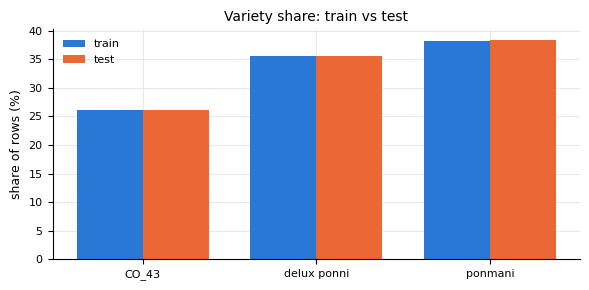

Variety share (%):
 Variety  CO_43  delux ponni  ponmani
all       26.1         35.6     38.3
train     26.2         35.6     38.3
test      26.1         35.6     38.3

Hectares share (%):
 Hectares   1    2    3    4    5   6
train    8.6 14.3 16.8 23.6 28.6 8.1
test       9 17.5   13 20.9 31.1 8.5

Agriblock share (%):
 Agriblock  Chinnasalem  Cuddalore  Kallakurichi  Kurinjipadi  Panruti  Sankarapuram
train             15.5       16.1          14.7         17.5     15.2          20.9
test              14.8       14.2          16.1         16.2     15.8          22.8


In [36]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df[TARGET])
print('train', train.shape, '| test', test.shape)

share = lambda d, c: d[c].value_counts(normalize=True).mul(100)
cls = pd.concat([share(df, TARGET).rename('all'), share(train, TARGET).rename('train'), share(test, TARGET).rename('test')], axis=1).loc[CLASSES]

fig, ax = plt.subplots(figsize=(6, 3))
x = np.arange(len(CLASSES)); w = 0.38
ax.bar(x - w/2, cls['train'], w, color=BLUE, label='train')
ax.bar(x + w/2, cls['test'], w, color=ORANGE, label='test')
ax.set(xticks=x, xticklabels=CLASSES, ylabel='share of rows (%)', title='Variety share: train vs test'); ax.legend()
plt.tight_layout(); plt.show()

print('Variety share (%):\n', cls.round(1).T.to_string())
for c in ['Hectares', 'Agriblock']:
    print(f'\n{c} share (%):\n', pd.concat([share(train, c).sort_index().rename('train'), share(test, c).sort_index().rename('test')], axis=1).round(1).T.to_string())

In [37]:
# ---- Amount of leakage if duplicates were kept (same seed, split before removing duplicates) ----
rs_tr, rs_te = train_test_split(raw, test_size=0.30, random_state=SEED, stratify=raw[TARGET])
hit = rs_te.merge(rs_tr.drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').mean()
print(f'If duplicates were kept, {hit:.1%} of TEST rows would have an exact copy (all 45 columns) in TRAIN.')

tw = test[FEATURES].merge(train[FEATURES].drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').mean()
print(f'After de-duplication, {tw:.1%} of test rows share their whole 44-feature vector with a training row.')

If duplicates were kept, 22.1% of TEST rows would have an exact copy (all 45 columns) in TRAIN.
After de-duplication, 0.0% of test rows share their whole 44-feature vector with a training row.


**Reading:**
* The split is representative: `Variety` shares are equal by construction (CO_43 26 %, delux ponni 36 %, ponmani 38 %), and `Hectares` / `Agriblock` shares are close
* Keeping duplicates would have let **22.1 %** of test rows be "answered from memory".
* After de-duplication, **0 %** of test feature vectors have a twin in train, so every test row is genuinely unseen.

# 4 · Target distribution
**Checks (Guideline):** balance, skewness, outliers. `Variety` is **nominal**, so only balance applies:
* **Skewness** needs an ordered numeric scale; class labels have no order, so it is undefined.
* **Outliers** are extreme values on a numeric scale; a label is either one of the 3 valid classes or not, which was already checked in the quality audit (all labels valid).

,count,share (%)
Variety,,
CO_43,428,26.1614
delux ponni,582,35.5746
ponmani,626,38.2641


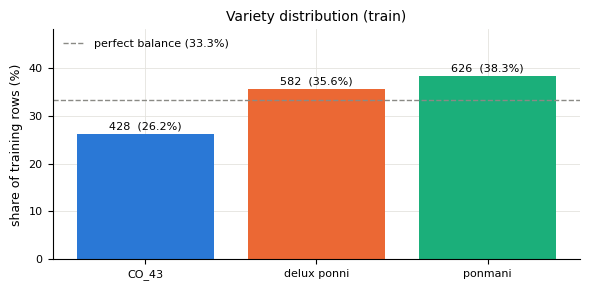

imbalance ratio (largest / smallest class): 1.46


In [38]:
tr = train.copy()                                    # <- all EDA and feature-selection cells from here on use `tr` (train only)

cnt = tr[TARGET].value_counts().reindex(CLASSES)
tgt = pd.DataFrame({'count': cnt, 'share (%)': cnt / cnt.sum() * 100})
display(tgt)

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(CLASSES, tgt['share (%)'], color=[BLUE, ORANGE, AQUA])
ax.bar_label(bars, labels=[f'{n}  ({p:.1f}%)' for n, p in zip(tgt['count'], tgt['share (%)'])], fontsize=8, padding=2)
ax.axhline(100 / len(CLASSES), color=GREY, ls='--', lw=1, label='perfect balance (33.3%)')
ax.set(ylabel='share of training rows (%)', title='Variety distribution (train)', ylim=(0, 48)); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

p = cnt / cnt.sum()
print(f'imbalance ratio (largest / smallest class): {cnt.max() / cnt.min():.2f}')

In [39]:
# ---- One-vs-Rest view: each binary sub-problem's positive share ----
ovr = pd.DataFrame({'positive (this variety)': cnt, 'negative (other two)': cnt.sum() - cnt})
ovr['positive share (%)'] = ovr.iloc[:, 0] / cnt.sum() * 100
ovr['neg / pos ratio'] = ovr.iloc[:, 1] / ovr.iloc[:, 0]
ovr.index = [f'{c} vs rest' for c in CLASSES]
ovr

,positive (this variety),negative (other two),positive share (%),neg / pos ratio
CO_43 vs rest,428,1208,26.1614,2.8224
delux ponni vs rest,582,1054,35.5746,1.811
ponmani vs rest,626,1010,38.2641,1.6134


### 4.1 Reading — target distribution
* **Balance:** 428 / 582 / 626 (CO_43 / delux ponni / ponmani) of 1,636 training rows. The largest/smallest ratio is 1.46, so the classes are **mildly imbalanced**: `CO_43` is the minority (26.2 %), the other two are close to each other.
* **One-vs-Rest:** splitting into 3 binary problems makes each one more imbalanced than the 3-class problem. `CO_43 vs rest` is the hardest at 2.8 negatives per positive.

**Discussion — target distribution: decisions**
* **No resampling**: a ratio of 1.46 is mild
* The 70/30 split already keeps these proportions in train and test.